Importando as bibliotecas

In [ ]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

In [ ]:
RANDOM_STATE = 42
BASE = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
CAMINHO_DADOS = BASE / 'data' / 'raw' / 'WineQT.csv'
TARGET = 'qualidade_do_vinho'
pd.set_option('display.max_columns', None)

1. Compreensão do problema

A avaliação da qualidade de um vinho geralmente é feita por especialistas, por meio de provas sensoriais. Esse processo pode levar tempo, ter um custo elevado e apresentar diferenças de avaliação entre os profissionais. Ao mesmo tempo, durante a produção, já são realizadas análises físico-químicas em laboratório, como as de acidez, teor alcoólico e sulfatos.

Diante disso, a proposta deste trabalho é utilizar os resultados dessas análises para prever se um vinho pode ser considerado de alta qualidade. Dessa forma, a vinícola teria uma forma de avaliar os lotes antes da prova sensorial, identificar aqueles com potencial para uma linha premium e perceber possíveis problemas com antecedência. O uso de machine learning é adequado para esse objetivo, pois a qualidade do vinho pode estar relacionada à combinação de diferentes características, e não apenas a uma variável isolada.

Na base de dados, a coluna quality apresenta notas de 0 a 10. Inicialmente, analisamos a distribuição dessas notas e, posteriormente, transformamos a variável em duas classes, conforme o critério apresentado na seção 2.2:

Alto: notas iguais ou superiores a 7.

Baixo/Médio: notas inferiores a 7.

In [ ]:
df_vinho = pd.read_csv(CAMINHO_DADOS)

### Fonte e dicionário de variáveis

A base é a WineQT, do Kaggle (Wine Quality Dataset).

As variáveis são:

- fixed acidity: acidez fixa, principalmente ácido tartárico (g/dm³)
- volatile acidity: acidez volátil, principalmente ácido acético (g/dm³)
- citric acid: ácido cítrico (g/dm³)
- residual sugar: açúcar que sobra depois da fermentação (g/dm³)
- chlorides: cloretos, quantidade de sal (g/dm³)
- free sulfur dioxide: dióxido de enxofre livre (mg/dm³)
- total sulfur dioxide: dióxido de enxofre total, livre + combinado (mg/dm³)
- density: densidade (g/cm³)
- pH: acidez em escala de pH
- sulphates: sulfatos (g/dm³)
- alcohol: teor alcoólico (% do volume)
- quality: nota de 0 a 10 dada por especialistas
- Id: numeração da linha, sem significado

In [ ]:
df_vinho.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
df_vinho.shape

(1143, 13)

In [ ]:
df_vinho.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [ ]:
nulos = df_vinho.isnull().sum()
pd.DataFrame({'nulos': nulos, '%': (nulos / len(df_vinho) * 100).round(2)})

,nulos,%
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0


Nenhuma coluna tem valores faltantes.

In [ ]:
df_vinho.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


### Duplicatas

Olhando a base com a coluna Id não aparece nenhuma linha duplicada, porque o Id é diferente em todas. O Id é só a numeração da linha, então tiramos ele e verificamos de novo.

In [ ]:
df_vinho.duplicated().sum()

np.int64(0)

In [ ]:
df_vinho = df_vinho.drop('Id', axis=1)
df_vinho.duplicated().sum()

np.int64(125)

In [ ]:
df_vinho = df_vinho.drop_duplicates()
df_vinho.shape

(1018, 12)

Removemos as duplicatas para que o mesmo vinho não caia no treino e no teste ao mesmo tempo.

## 2. Análise exploratória

### 2.1 Análise pela nota (quality)

In [ ]:
df_vinho['quality'].value_counts()

,count
quality,
5,433
6,409
7,122
4,33
8,15
3,6


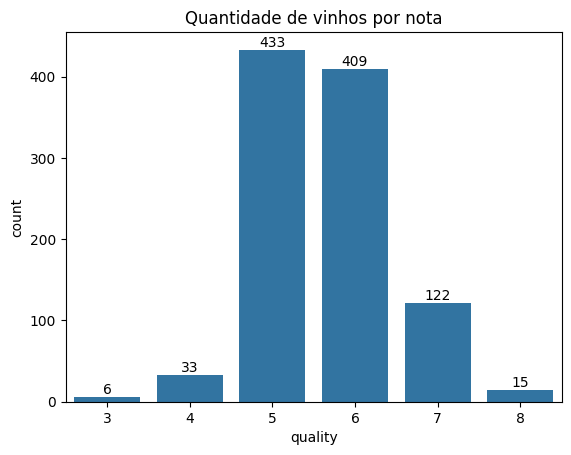

In [ ]:
ax = sns.countplot(x='quality', data=df_vinho)
ax.bar_label(ax.containers[0])
plt.title('Quantidade de vinhos por nota')
plt.show()

A maior parte dos vinhos tem nota 5 ou 6 e não existe nenhum vinho com nota acima de 8. Notas muito baixas (3 e 4) e muito altas (8) são raras.

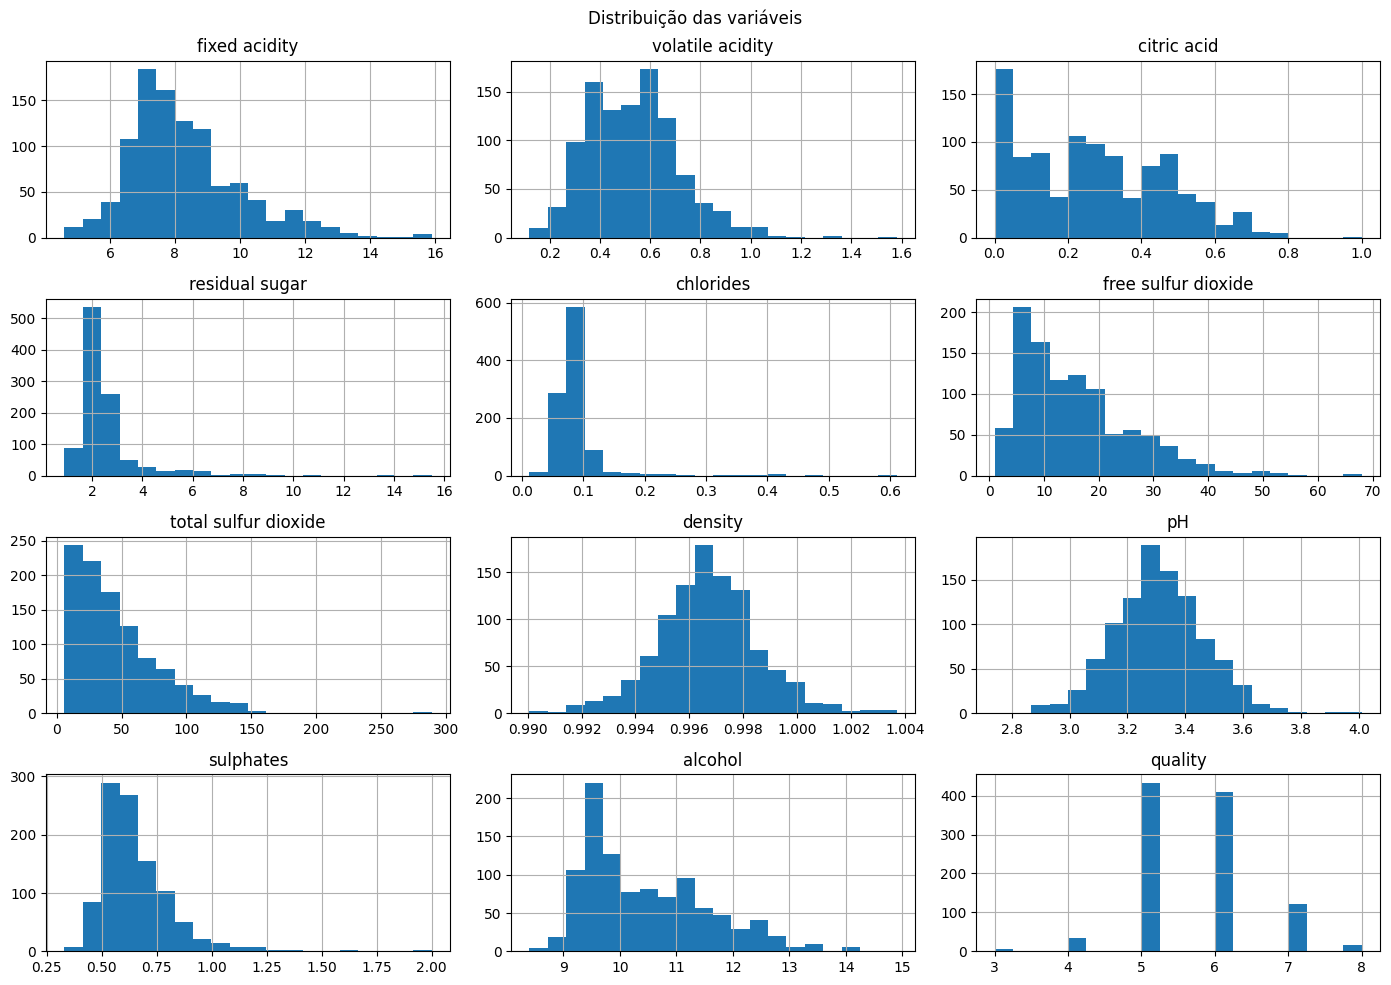

In [ ]:
df_vinho.hist(figsize=(14, 10), bins=20)
plt.suptitle('Distribuição das variáveis')
plt.tight_layout()
plt.show()

In [ ]:
df_vinho.drop('quality', axis=1).skew().sort_values(ascending=False)

,0
chlorides,5.933225
residual sugar,4.350318
sulphates,2.424667
total sulfur dioxide,1.680327
free sulfur dioxide,1.172090
fixed acidity,1.037193
alcohol,0.848859
volatile acidity,0.719668
citric acid,0.368824
pH,0.257993


Chlorides, residual sugar, sulphates e os dióxidos de enxofre têm a distribuição bem puxada para a direita (poucos vinhos com valores muito altos). Density e pH são mais simétricas. As variáveis também estão em escalas diferentes.

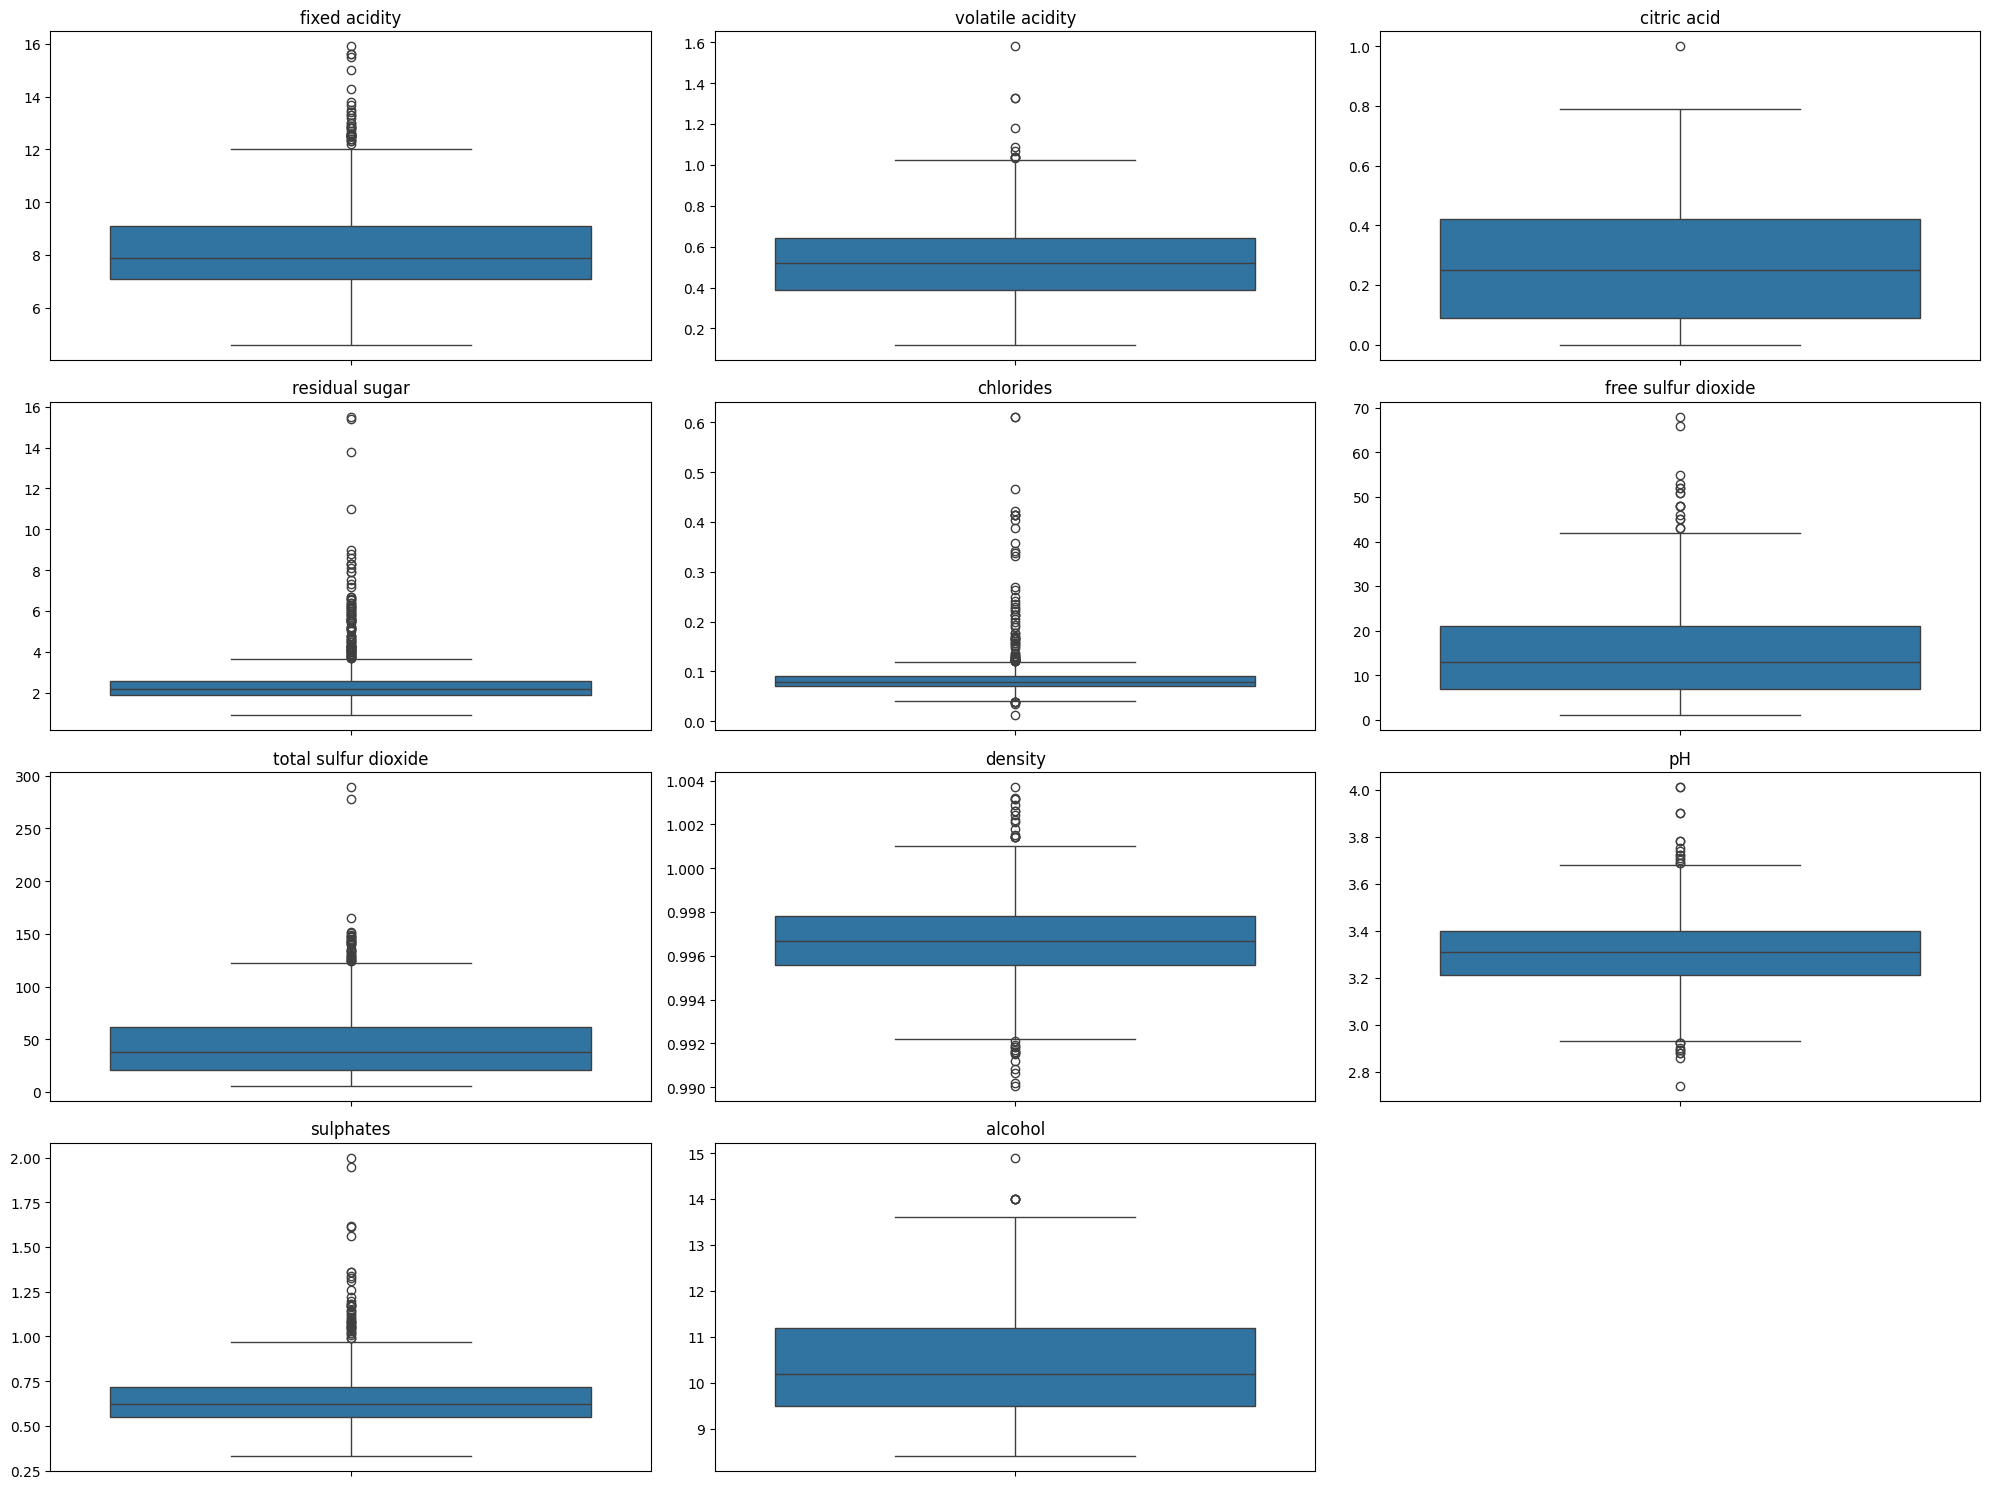

In [ ]:
colunas = df_vinho.columns.drop('quality')

plt.figure(figsize=(20,15))
for i, coluna in enumerate(colunas):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(y=df_vinho[coluna])
    plt.title(coluna)
    plt.ylabel('')
plt.tight_layout()
plt.show()

In [ ]:
for coluna in colunas:
    q1 = df_vinho[coluna].quantile(0.25)
    q3 = df_vinho[coluna].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df_vinho[coluna] < q1 - 1.5 * iqr) | (df_vinho[coluna] > q3 + 1.5 * iqr)).sum()
    print(coluna, outliers)

fixed acidity 37
volatile acidity 10
citric acid 1
residual sugar 95
chlorides 71
free sulfur dioxide 16
total sulfur dioxide 33
density 30
pH 24
sulphates 41
alcohol 6


In [ ]:
print((df_vinho < 0).sum().sum())
print(df_vinho[(df_vinho['pH'] < 2) | (df_vinho['pH'] > 5)].shape[0])
print(df_vinho[df_vinho['free sulfur dioxide'] > df_vinho['total sulfur dioxide']].shape[0])

0
0
0


Existem outliers principalmente em residual sugar, chlorides e sulphates, mas decidimos não remover. São valores possíveis para um vinho (mais sal, mais açúcar, mais sulfato) e não erro de medição. Também não encontramos valores inconsistentes: nada negativo, pH dentro do normal e o SO2 livre nunca é maior que o total.

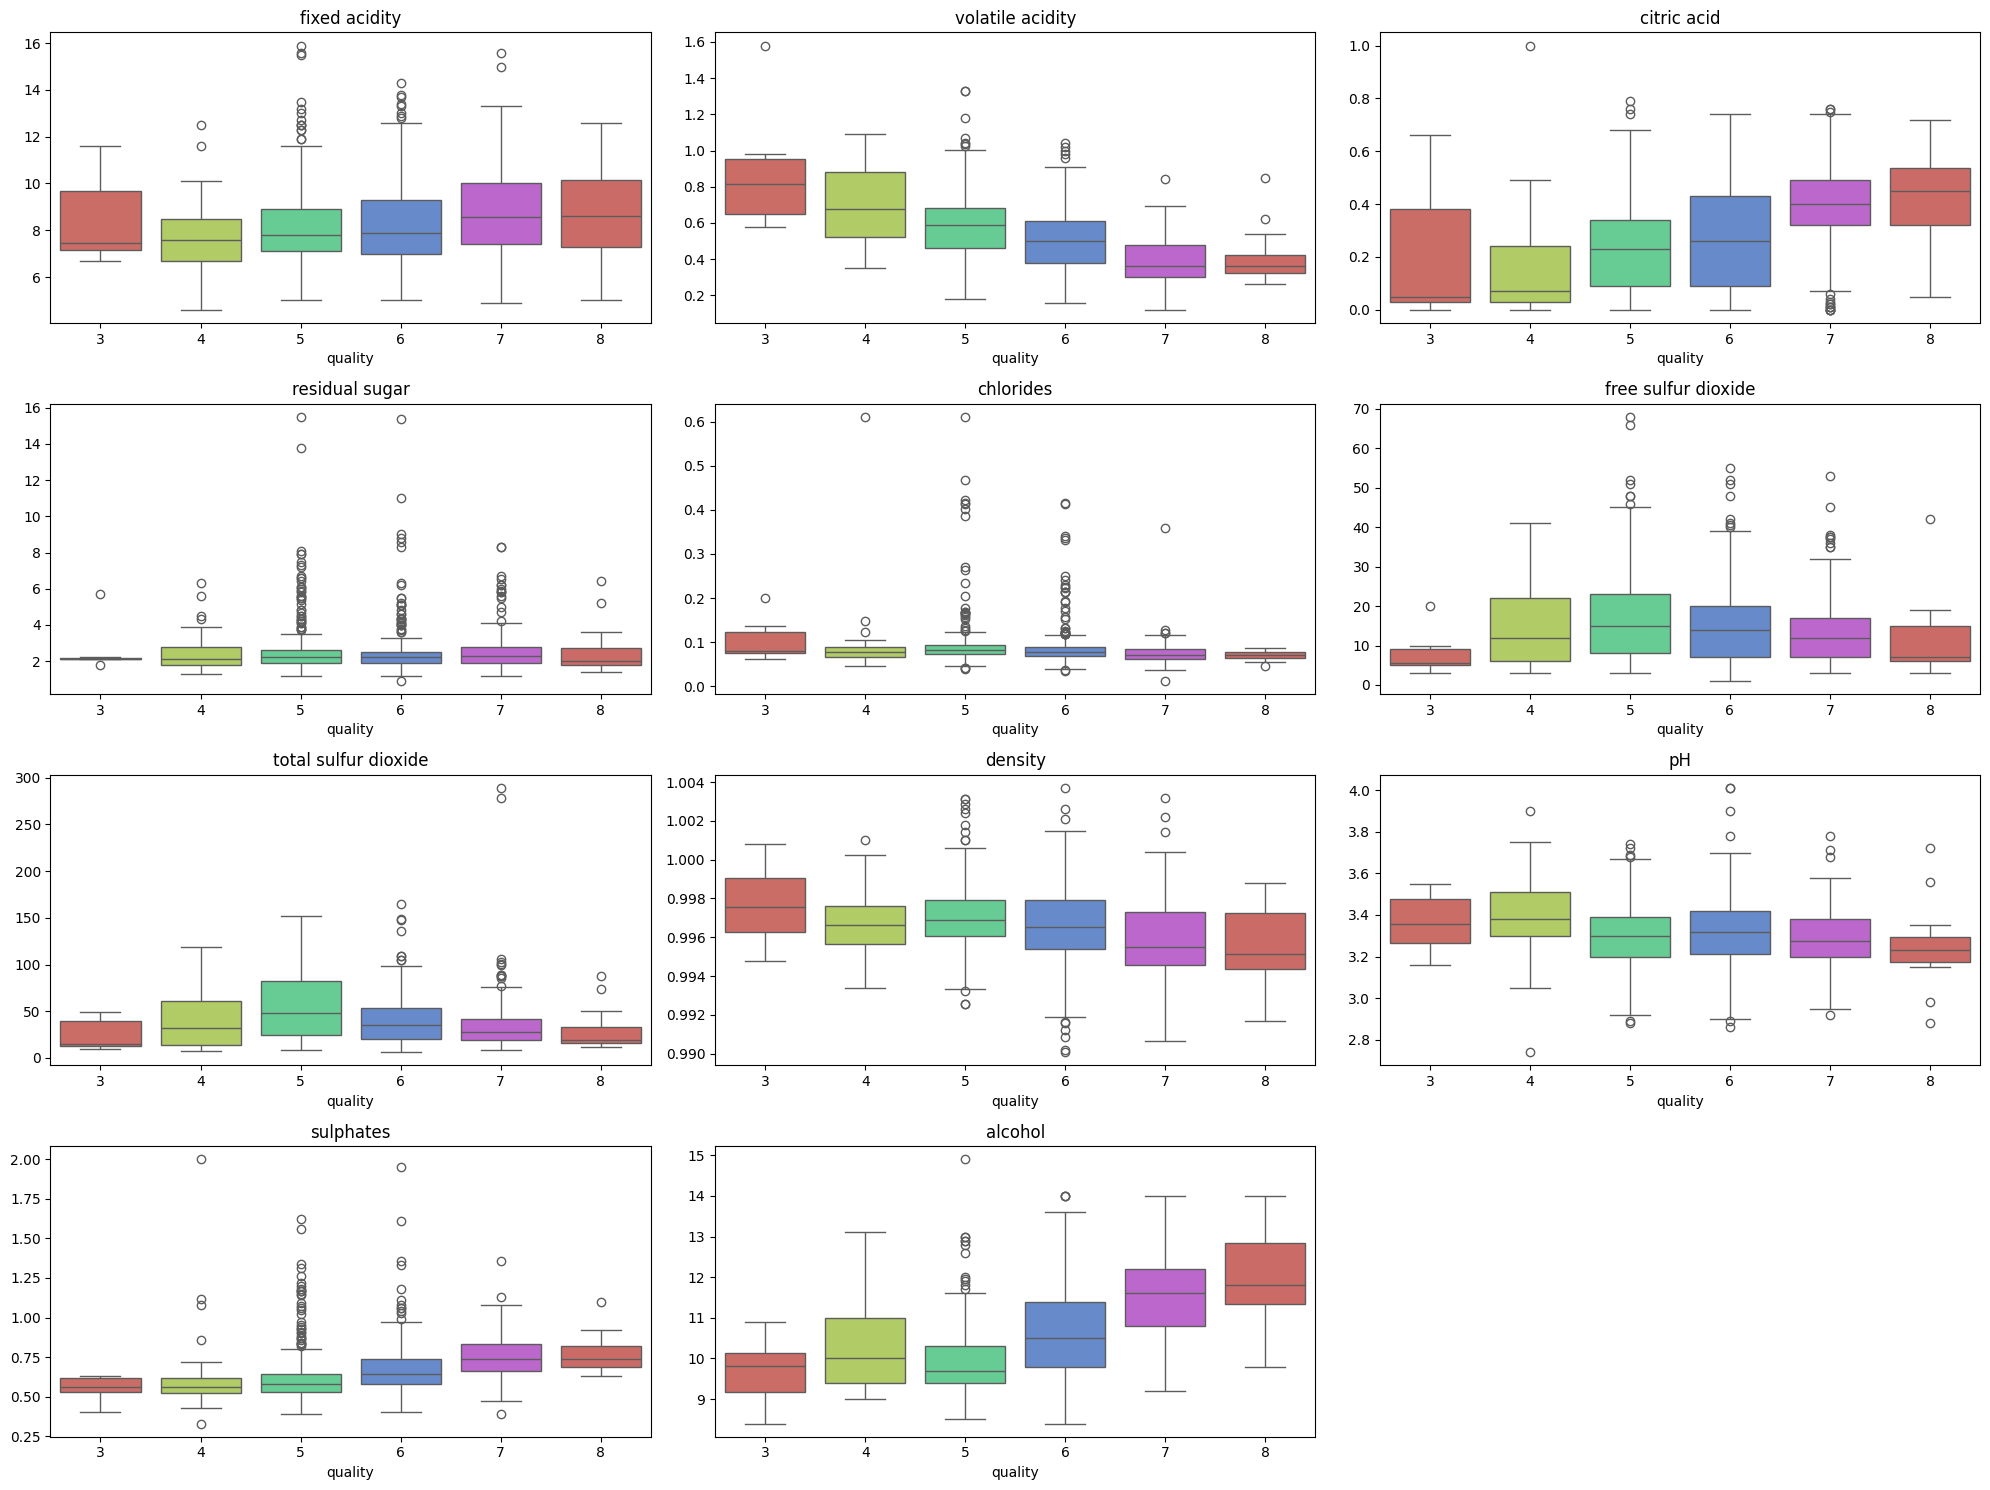

In [ ]:
plt.figure(figsize=(20,15))
for i, coluna in enumerate(colunas):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(x='quality', y=coluna, data=df_vinho, hue='quality', palette='hls', legend=False)
    plt.title(coluna)
    plt.ylabel('')
plt.tight_layout()
plt.show()

Nos boxplots por nota, alcohol, sulphates e citric acid sobem conforme a nota aumenta, e volatile acidity cai. Essa diferença fica mais clara a partir da nota 7. Nas outras variáveis as caixas das notas ficam bem parecidas.

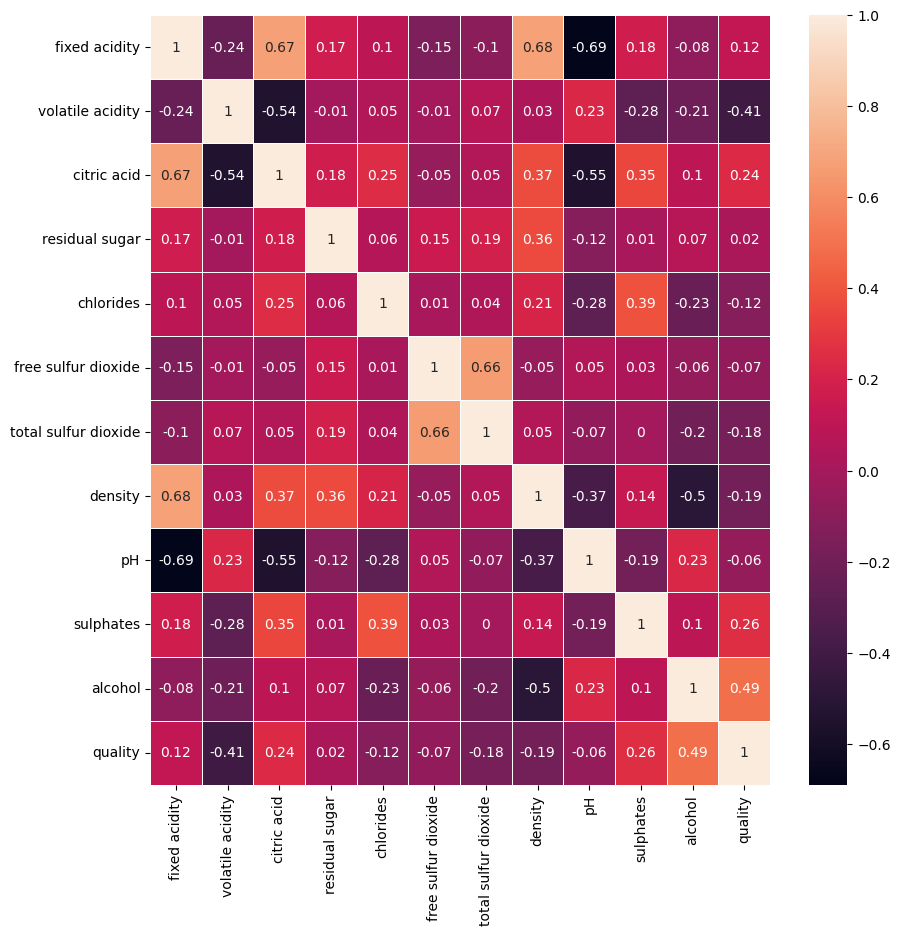

In [ ]:
correlation_matrix = df_vinho.corr().round(2)

fig, ax = plt.subplots(figsize=(10,10))
sns.heatmap(data=correlation_matrix, annot=True, linewidths=.5, ax=ax)
plt.show()

Análise das correlações

Ao analisar a relação entre as variáveis físico-químicas e a qualidade, observamos que o teor alcoólico (alcohol) tende a aumentar junto com a nota do vinho. Já a acidez volátil (volatile acidity) apresenta o comportamento contrário, com valores menores associados a notas mais altas. As variáveis sulphates e citric acid também apresentam uma relação positiva com a qualidade.

Também identificamos algumas relações entre as próprias características dos vinhos. A acidez fixa (fixed acidity) apresenta correlação negativa com o pH, o que faz sentido, já que uma maior acidez geralmente está associada a um pH menor. Além disso, a acidez fixa se relaciona com o ácido cítrico (citric acid) e com a densidade (density).

As variáveis free sulfur dioxide e total sulfur dioxide também apresentam uma correlação positiva, pois o dióxido de enxofre livre faz parte da quantidade total presente no vinho. Outra relação observada foi entre o álcool e a densidade, que apresentam correlação negativa.

Apesar dessas relações, nenhuma das correlações observadas entre as variáveis foi considerada alta o suficiente para justificar a exclusão de alguma característica antes do treinamento dos modelos.

### 2.2 Análise pela categoria (Baixo/Médio x Alto)

#### Definição da variável alvo

Transformamos a nota em duas categorias usando o limiar de 7.

In [ ]:
def qualidade_do_vinho (qualidade):
  if qualidade < 7:
    return 0  #Qualidade Baixa/Média
  else:
    return 1 #Qualidade Alta

In [ ]:
df_vinho[TARGET] = df_vinho['quality'].apply(qualidade_do_vinho)

In [ ]:
df_vinho.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,qualidade_do_vinho
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [ ]:
df = df_vinho.drop('quality',axis=1)

In [ ]:
nomes = {0: 'Baixo/Médio', 1: 'Alto'}
df_grafico = df.copy()
df_grafico['qualidade_do_vinho'] = df_grafico['qualidade_do_vinho'].map(nomes)

In [ ]:
df_grafico['qualidade_do_vinho'].value_counts(normalize=True)

,proportion
qualidade_do_vinho,
Baixo/Médio,0.865422
Alto,0.134578


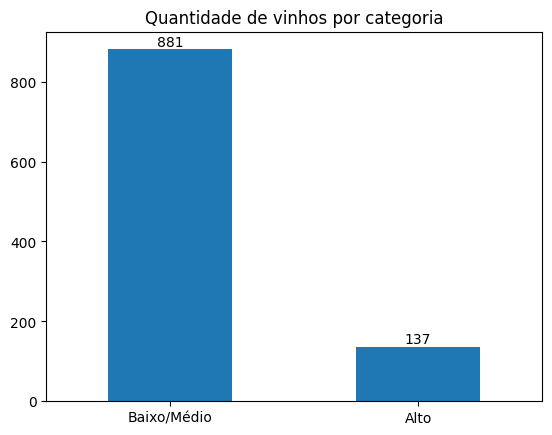

In [ ]:
ax = df_grafico['qualidade_do_vinho'].value_counts().plot(kind='bar', rot=0)
ax.bar_label(ax.containers[0])
plt.title('Quantidade de vinhos por categoria')
plt.xlabel('')
plt.show()

Só cerca de 13% dos vinhos são de qualidade alta, ou seja, as classes estão desbalanceadas. Por isso não dá para olhar só a acurácia: um modelo que prediz sempre "Baixo/Médio" já acertaria por volta de 86%.

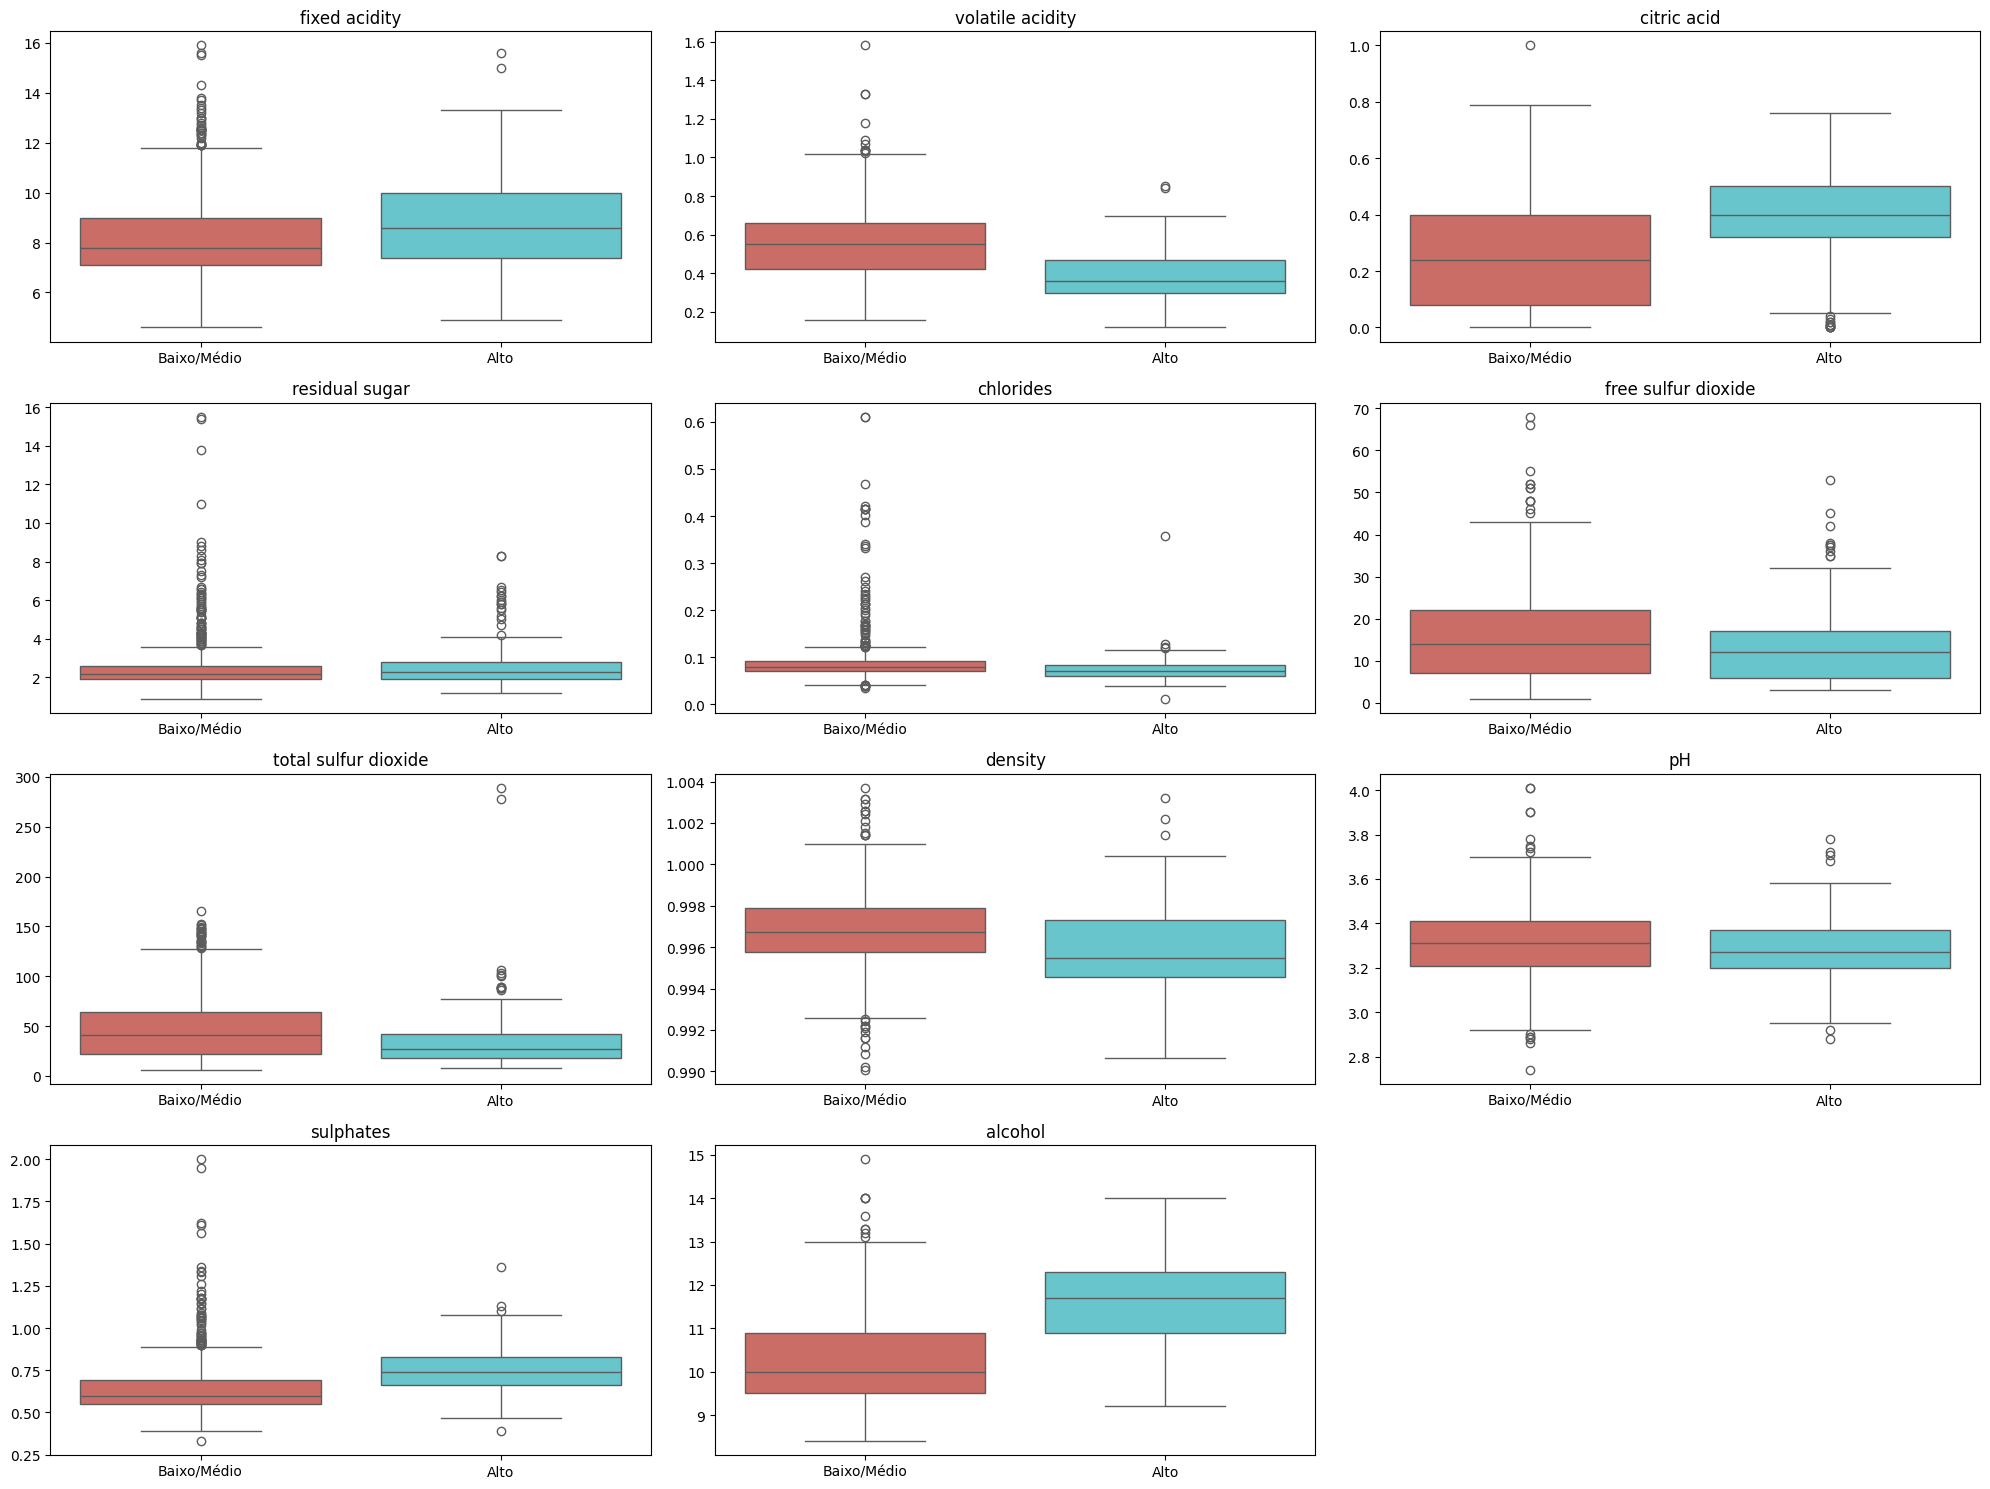

In [ ]:
plt.figure(figsize=(20,15))
for i, coluna in enumerate(colunas):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(x='qualidade_do_vinho', y=coluna, data=df_grafico, hue='qualidade_do_vinho', palette='hls', legend=False, order=['Baixo/Médio', 'Alto'])
    plt.title(coluna)
    plt.xlabel('')
    plt.ylabel('')
plt.tight_layout()
plt.show()

In [ ]:
df_grafico.groupby('qualidade_do_vinho')[colunas].median().T

qualidade_do_vinho,Alto,Baixo/Médio
fixed acidity,8.60000,7.80000
volatile acidity,0.36000,0.55000
citric acid,0.40000,0.24000
residual sugar,2.30000,2.20000
chlorides,0.07100,0.08000
free sulfur dioxide,12.00000,14.00000
total sulfur dioxide,27.00000,41.00000
density,0.99549,0.99675
pH,3.27000,3.31000
sulphates,0.74000,0.60000


Os boxplots e as medianas confirmam a análise por nota: os vinhos Alto têm mais alcohol, menos volatile acidity, mais sulphates e mais citric acid. Nas outras variáveis as caixas das duas categorias se sobrepõem bastante.

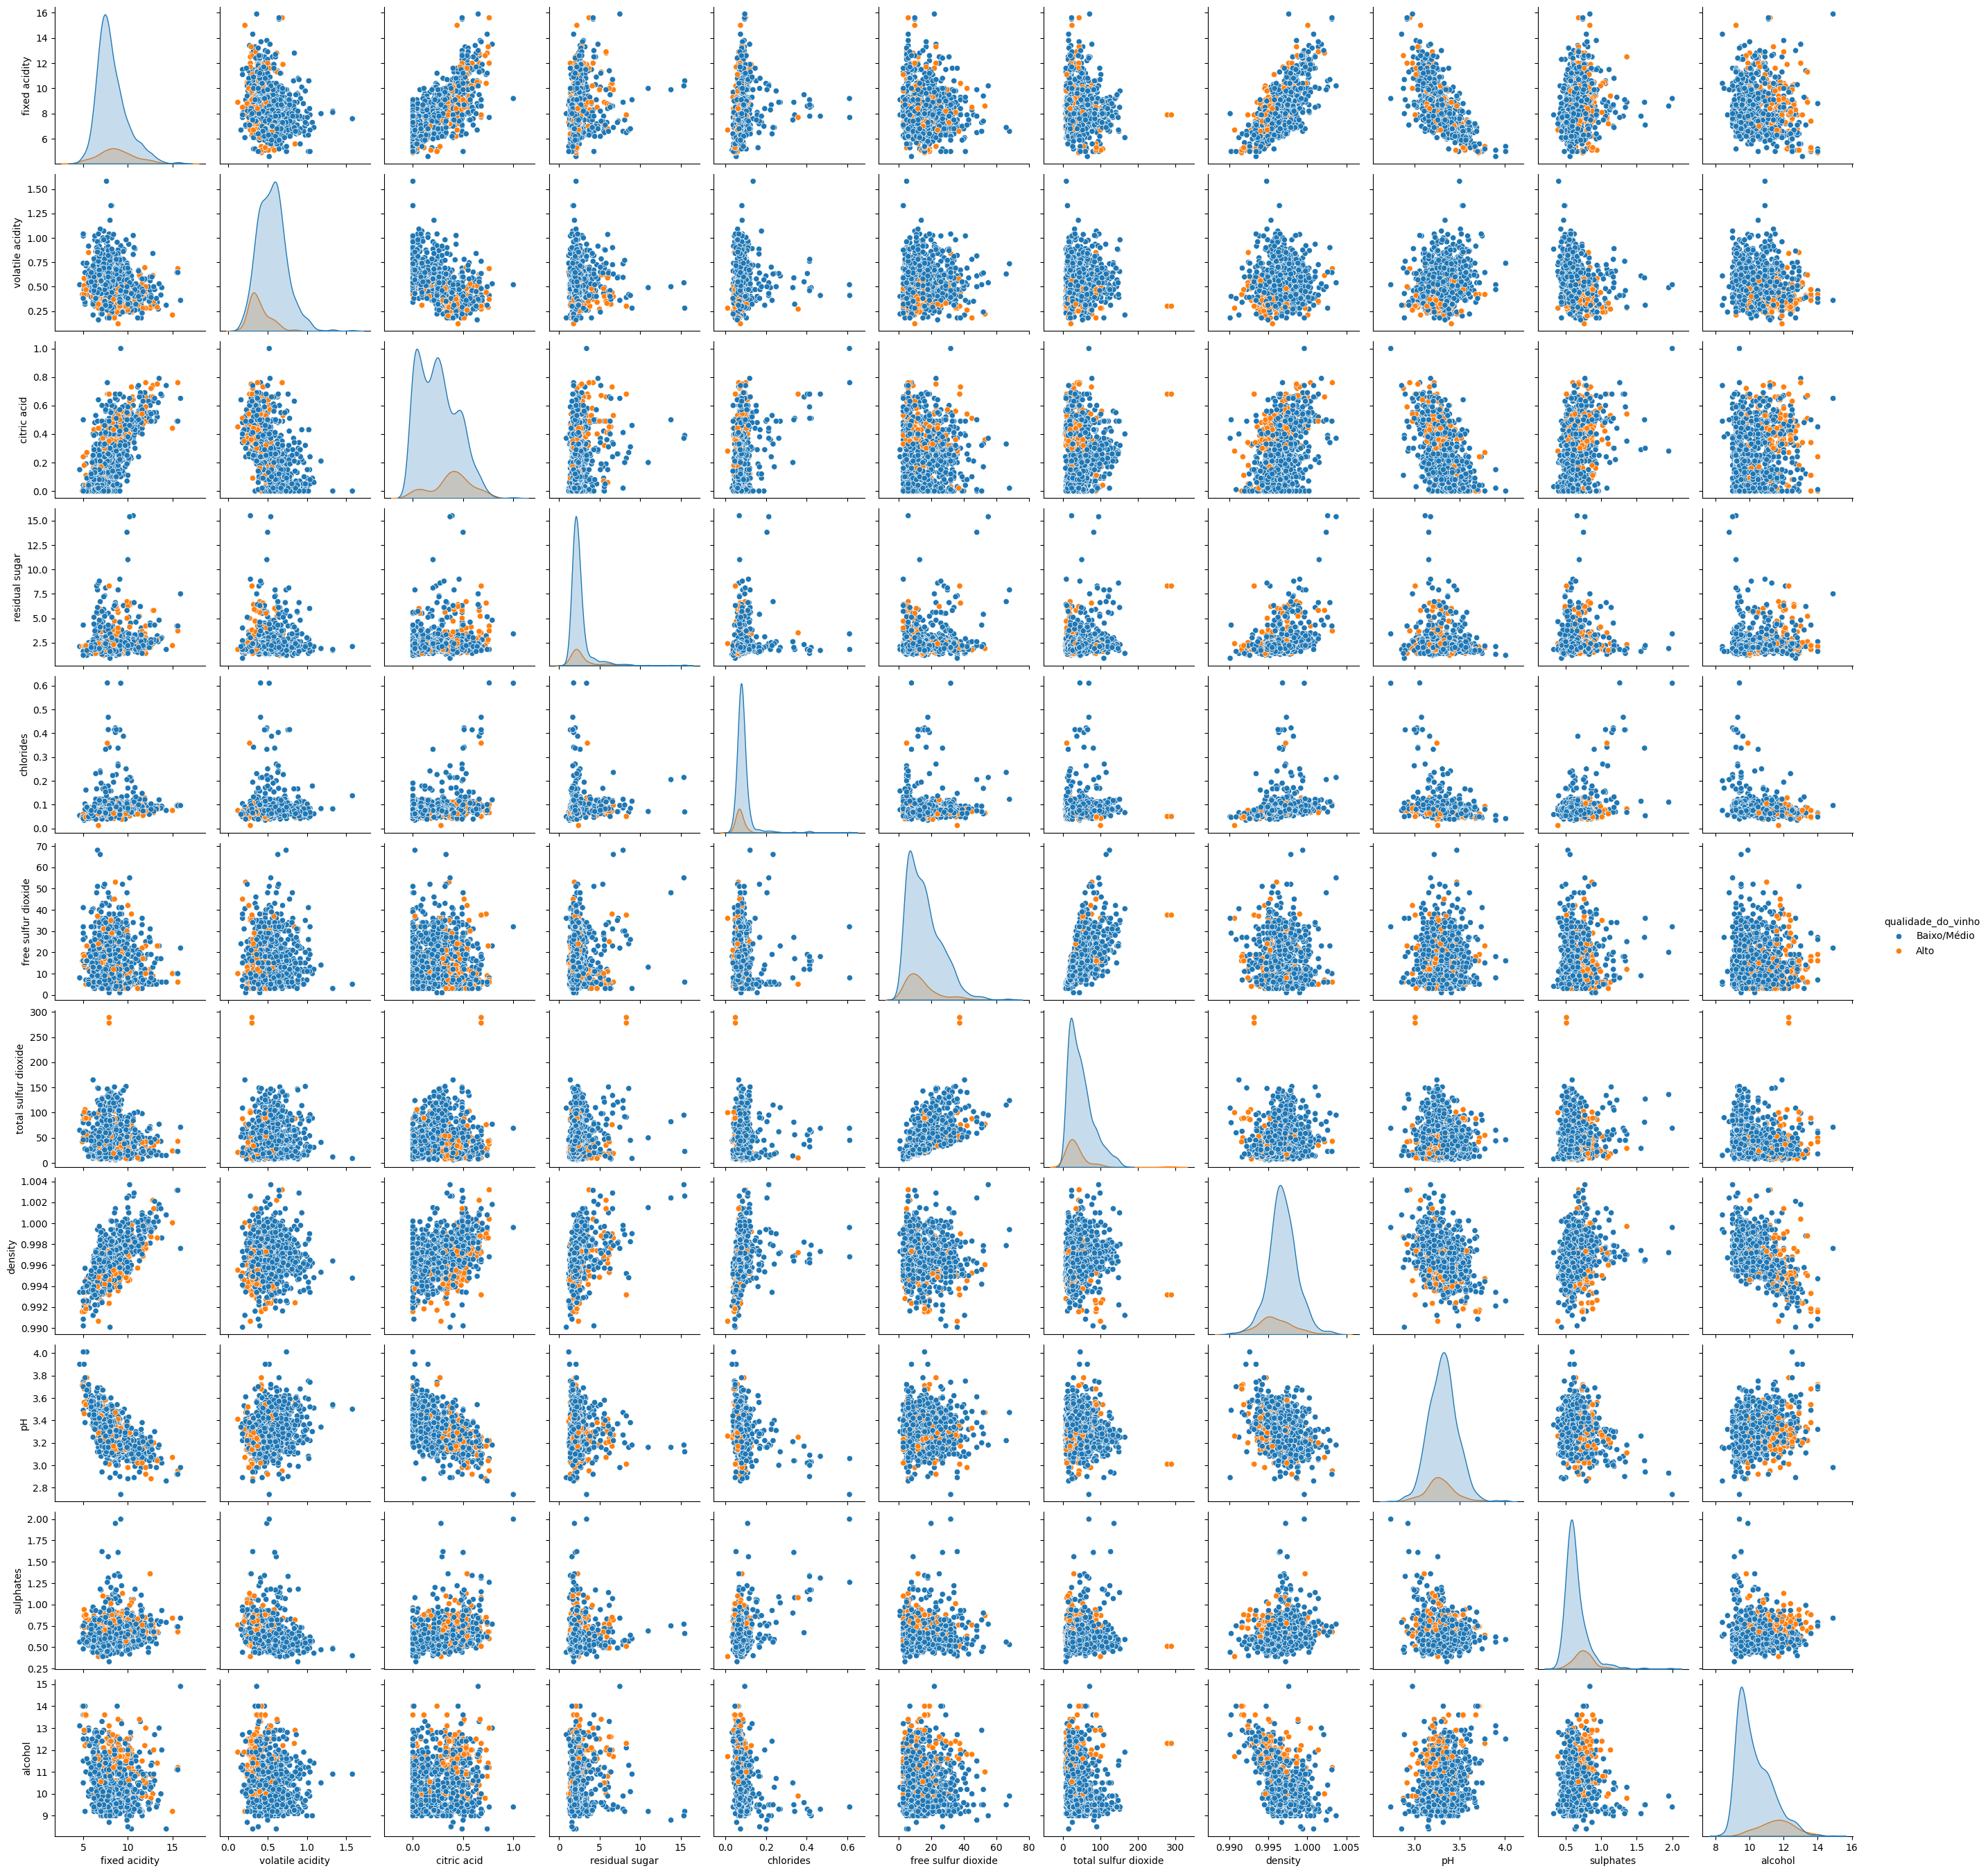

In [ ]:
sns.pairplot(df_grafico, vars=colunas, hue='qualidade_do_vinho')

No pairplot, nenhuma variável sozinha separa as duas categorias. Os vinhos Alto ficam mais concentrados na região de álcool alto e acidez volátil baixa, mas ainda misturados com vinhos Baixo/Médio. Por isso faz sentido usar modelos que combinam várias variáveis ao mesmo tempo.

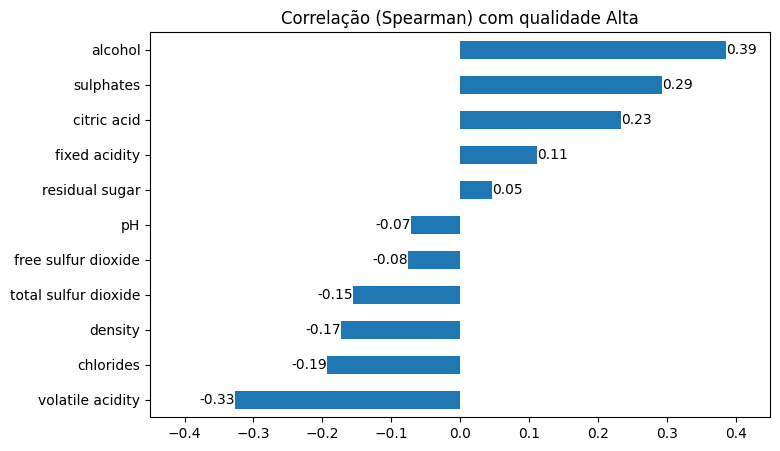

In [ ]:
correlacao = df.corr(method='spearman')['qualidade_do_vinho'].drop('qualidade_do_vinho').sort_values()
ax = correlacao.plot(kind='barh', figsize=(8,5))
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.title('Correlação (Spearman) com qualidade Alta')
plt.xlim(-0.45, 0.45)
plt.show()

Aqui usamos a correlação de Spearman porque várias variáveis têm outliers e distribuição assimétrica, e ela é menos afetada por isso.

Correlações com a qualidade Alta e sua consequência nos vinhos:
- alcohol (positiva): vinhos com fermentação completa e uvas mais maduras têm mais álcool, o que dá mais corpo ao vinho.
- sulphates (positiva): o sulfato funciona como conservante e antioxidante, ajudando a manter o aroma.
- citric acid (positiva): dá frescor ao vinho.
- volatile acidity (negativa): é principalmente ácido acético. Em excesso deixa o vinho com cheiro de vinagre.
- chlorides (negativa): muito sal deixa o vinho desequilibrado.
- density (negativa): está ligada ao álcool. O álcool é menos denso que a água, então quanto mais álcool, menor a densidade.
- total sulfur dioxide (negativa): SO2 em excesso aparece no aroma.

3. Pré-processamento

Antes de treinar os modelos, verificamos quais ajustes seriam necessários na base de dados.

Dados faltantes: não foram encontrados valores ausentes na análise apresentada na seção 1. Por isso, não foi necessário preencher ou excluir registros por esse motivo.

Duplicatas: foram removidas 125 linhas duplicadas, conforme apresentado na seção 1.

Outliers: os valores extremos foram mantidos, pois não foram identificados motivos suficientes para considerá-los erros de medição. Essa decisão é discutida na seção 2.1.

Variável alvo: a coluna quality foi convertida em uma variável binária, separando os vinhos em Alto (nota igual ou superior a 7) e Baixo/Médio (nota inferior a 7).

Padronização: utilizamos o StandardScaler para colocar as variáveis em escalas comparáveis. Essa etapa é importante porque existem diferenças consideráveis entre os valores das características, como ocorre com total sulfur dioxide, que pode chegar próximo de 300, e density, cujos valores ficam próximos de 1. A Regressão Logística pode ser afetada por essas diferenças de escala, enquanto a Árvore de Decisão e o Random Forest não dependem da padronização da mesma forma.

Para evitar o vazamento de informações, o StandardScaler foi incluído em um Pipeline, conforme apresentado na seção 4.3. Assim, durante a validação cruzada, o ajuste da escala é feito apenas com os dados de treinamento de cada divisão, sem utilizar informações da parte reservada para validação.

Criação de novas variáveis: optamos por manter as 11 variáveis originais da base. Embora tenhamos considerado criar características, mantivemos o conjunto original de características.

## 4. Modelos


Para realizar a previsão da qualidade dos vinhos, escolhemos três modelos de classificação: Regressão Logística, Árvore de Decisão e Random Forest. A escolha permite comparar métodos com características diferentes.

Regressão Logística: é um modelo linear que estima a probabilidade de um vinho pertencer à classe Alto. Seus coeficientes ajudam a entender como cada variável está relacionada à previsão.

Árvore de Decisão: utiliza divisões baseadas nos valores das variáveis para classificar os vinhos. Isso permite representar o processo de decisão por meio de regras, tornando o resultado mais fácil de interpretar.

Random Forest: combina várias árvores de decisão para produzir uma classificação. Essa abordagem permite considerar relações mais complexas entre as características dos vinhos.

Os modelos foram avaliados em três etapas, para verificar os resultados tanto com as configurações iniciais quanto após o ajuste dos parâmetros:

Modelos sem ajuste: treinamento com os dados originais e parâmetros padrão.

Modelos com GridSearchCV: busca pelas melhores combinações de parâmetros utilizando os dados originais.

Modelos com GridSearchCV e padronização: repetição do ajuste com o StandardScaler integrado a um Pipeline.

Ao final de cada etapa, avaliamos o desempenho dos modelos no conjunto de teste. Além da acurácia, analisamos a precisão (precision), o recall e o F1-score da classe Alto. Essas métricas são importantes porque a quantidade de vinhos em cada classe é diferente, o que significa que a acurácia, quando analisada sozinha, pode não representar adequadamente a capacidade do modelo de identificar vinhos de alta qualidade.

In [ ]:
X = df.drop(TARGET, axis=1)
y = df[TARGET]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f'Treino: {X_train.shape[0]} amostras')
print(f'Teste: {X_test.shape[0]} amostras')

Treino: 814 amostras
Teste: 204 amostras


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### 4.1 Modelos sem ajuste (dados originais)

Primeiro treinamos os três modelos com os parâmetros padrão. Além do resultado no teste, calculamos o F1 com validação cruzada: o treino é dividido em 5 partes, o modelo treina em 4 e é avaliado na que sobrou, repetindo 5 vezes. Assim o resultado não depende de uma única divisão dos dados.

In [ ]:
modelos = {
    'Regressão Logística': LogisticRegression(random_state=RANDOM_STATE, class_weight='balanced', max_iter=5000),
    'Árvore de Decisão': DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced')
}

In [ ]:
resultado_base = []
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_predito = modelo.predict(X_test)
    f1_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring='f1').mean()
    resultado_base.append([nome,
                           accuracy_score(y_test, y_predito),
                           precision_score(y_test, y_predito),
                           recall_score(y_test, y_predito),
                           f1_score(y_test, y_predito),
                           f1_cv])

resultado_base = pd.DataFrame(resultado_base, columns=['Modelo', 'Taxa de acerto', 'Precisão', 'Recall', 'F1', 'F1 (validação cruzada)']).round(2)
resultado_base

,Modelo,Taxa de acerto,Precisão,Recall,F1,F1 (validação cruzada)
0,Regressão Logística,0.79,0.37,0.81,0.51,0.49
1,Árvore de Decisão,0.84,0.41,0.48,0.44,0.40
2,Random Forest,0.91,0.90,0.33,0.49,0.36


Sem nenhum ajuste, o Random Forest teve a maior taxa de acerto no teste (0,90) e o melhor F1 (0,62). Mas na validação cruzada o F1 dele foi 0,50, igual ao da Regressão Logística (0,49). Ou seja, nesse teste específico ele foi bem, mas nas outras divisões do treino o resultado foi menor. A Árvore de Decisão sem limite de profundidade foi a pior (F1 de 0,40 na validação cruzada), porque cresce até decorar o treino.

### 4.2 Modelos com GridSearchCV (dados originais)

O GridSearchCV testa todas as combinações de parâmetros que passamos e escolhe a que tem o melhor F1 na validação cruzada, usando só os dados de treino.

In [ ]:
parametros = {
    'Regressão Logística': {
        'C': [0.001, 0.01, 0.1, 1, 10, 100]
    },
    'Árvore de Decisão': {
        'max_depth': [3, 4, 5, 6, 8, None],
        'min_samples_leaf': [1, 5, 10, 20],
        'criterion': ['gini', 'entropy']
    },
    'Random Forest': {
        'n_estimators': [100, 300],
        'max_depth': [None, 5, 10],
        'min_samples_leaf': [1, 3, 5],
        'criterion': ['gini', 'entropy']
    }
}

In [ ]:
resultado_grid = []
for nome, modelo in modelos.items():
    grid = GridSearchCV(modelo, parametros[nome], cv=cv, scoring='f1', n_jobs=-1)
    grid.fit(X_train, y_train)
    y_predito = grid.predict(X_test)
    print(nome, grid.best_params_)
    resultado_grid.append([nome,
                           accuracy_score(y_test, y_predito),
                           precision_score(y_test, y_predito),
                           recall_score(y_test, y_predito),
                           f1_score(y_test, y_predito),
                           grid.best_score_])

resultado_grid = pd.DataFrame(resultado_grid, columns=['Modelo', 'Taxa de acerto', 'Precisão', 'Recall', 'F1', 'F1 (validação cruzada)']).round(2)
resultado_grid

Regressão Logística {'C': 10}
Árvore de Decisão {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1}
Random Forest {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}


,Modelo,Taxa de acerto,Precisão,Recall,F1,F1 (validação cruzada)
0,Regressão Logística,0.80,0.38,0.81,0.52,0.50
1,Árvore de Decisão,0.81,0.40,0.78,0.52,0.49
2,Random Forest,0.89,0.56,0.67,0.61,0.55


Com o GridSearchCV, o F1 na validação cruzada melhorou nos três modelos:
- Árvore de Decisão: de 0,40 para 0,49, limitando a profundidade em 5.
- Random Forest: de 0,50 para 0,54, com no mínimo 3 vinhos por folha.
- Regressão Logística: de 0,49 para 0,50, com C = 10.

No teste, o Random Forest ajustado encontrou mais vinhos Alto (recall de 0,63 para 0,74), mas também passou a marcar mais vinhos comuns como Alto, por isso a taxa de acerto caiu de 0,90 para 0,87. Como o teste tem só 27 vinhos Alto, confiamos mais na validação cruzada para escolher os parâmetros.

### 4.3 Modelos com GridSearchCV (dados padronizados)

Agora repetimos o GridSearchCV com os dados padronizados. O StandardScaler fica dentro de um Pipeline junto com o modelo, assim em cada parte da validação cruzada ele é ajustado só com os dados de treino daquela parte, e o teste nunca influencia a padronização.

In [ ]:
grids_padronizados = {}
resultado_grid_padronizado = []
for nome, modelo in modelos.items():
    pipeline = Pipeline([('scaler', StandardScaler()), ('modelo', modelo)])
    parametros_pipeline = {'modelo__' + chave: valores for chave, valores in parametros[nome].items()}
    grid = GridSearchCV(pipeline, parametros_pipeline, cv=cv, scoring='f1', n_jobs=-1)
    grid.fit(X_train, y_train)
    grids_padronizados[nome] = grid
    y_predito = grid.predict(X_test)
    print(nome, grid.best_params_)
    resultado_grid_padronizado.append([nome,
                                       accuracy_score(y_test, y_predito),
                                       precision_score(y_test, y_predito),
                                       recall_score(y_test, y_predito),
                                       f1_score(y_test, y_predito),
                                       grid.best_score_])

resultado_grid_padronizado = pd.DataFrame(resultado_grid_padronizado, columns=['Modelo', 'Taxa de acerto', 'Precisão', 'Recall', 'F1', 'F1 (validação cruzada)']).round(2)
resultado_grid_padronizado

Regressão Logística {'modelo__C': 100}
Árvore de Decisão {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 1}
Random Forest {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 100}


,Modelo,Taxa de acerto,Precisão,Recall,F1,F1 (validação cruzada)
0,Regressão Logística,0.79,0.36,0.78,0.49,0.52
1,Árvore de Decisão,0.81,0.40,0.78,0.52,0.49
2,Random Forest,0.86,0.49,0.74,0.59,0.54


A padronização só mudou a Regressão Logística: o F1 na validação cruzada subiu de 0,50 para 0,52 e o melhor C mudou de 10 para 100. No teste o F1 dela ficou em 0,49, um vinho Alto a menos que na etapa anterior, o que está dentro da variação esperada com só 27 vinhos Alto. Isso era esperado, porque a Regressão Logística depende da escala das variáveis.

Na Árvore de Decisão o resultado foi idêntico, e no Random Forest praticamente igual, porque as árvores só comparam valores ("álcool maior que X") e a escala não altera essa comparação.

### 4.4 Comparação das três etapas

In [ ]:
comparacao_acerto = pd.DataFrame({
    'Sem ajuste': resultado_base.set_index('Modelo')['Taxa de acerto'],
    'GridSearch': resultado_grid.set_index('Modelo')['Taxa de acerto'],
    'GridSearch + padronizado': resultado_grid_padronizado.set_index('Modelo')['Taxa de acerto']
})

comparacao_f1 = pd.DataFrame({
    'Sem ajuste': resultado_base.set_index('Modelo')['F1'],
    'GridSearch': resultado_grid.set_index('Modelo')['F1'],
    'GridSearch + padronizado': resultado_grid_padronizado.set_index('Modelo')['F1']
})

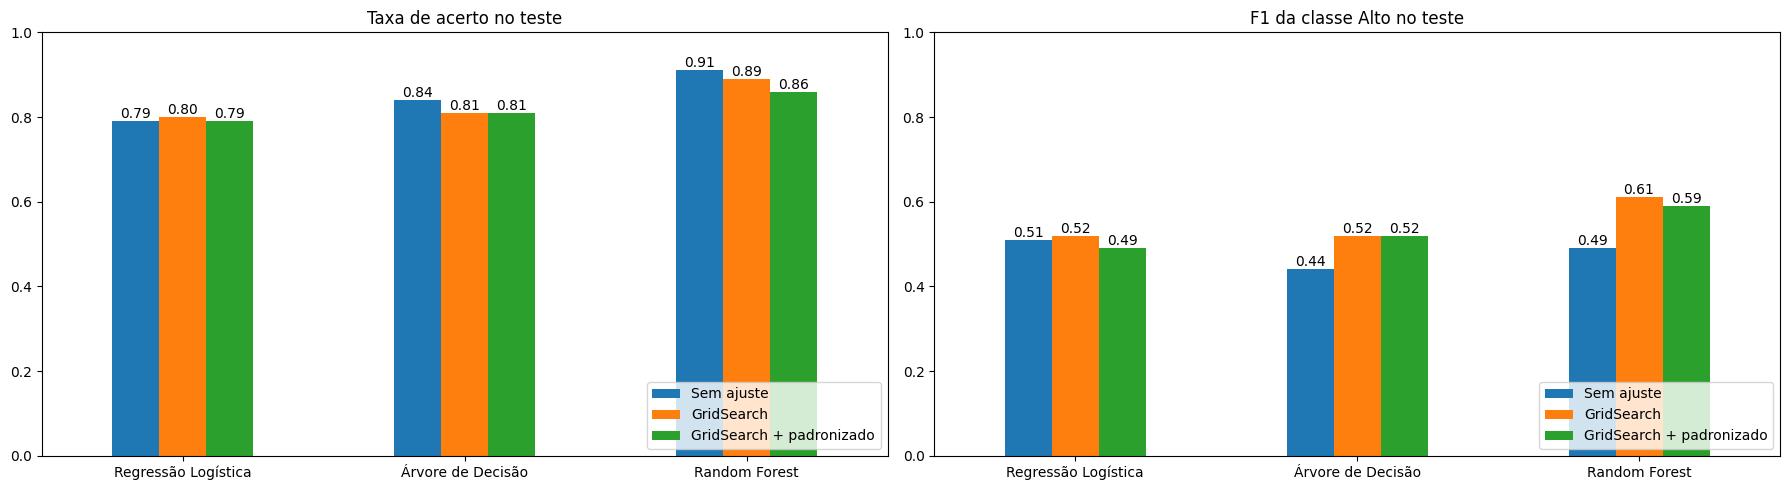

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18,5))

comparacao_acerto.plot(kind='bar', rot=0, ax=axes[0])
axes[0].set_title('Taxa de acerto no teste')
axes[0].set_ylim(0, 1)

comparacao_f1.plot(kind='bar', rot=0, ax=axes[1])
axes[1].set_title('F1 da classe Alto no teste')
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel('')
    ax.legend(loc='lower right')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f')
plt.tight_layout()
plt.show()

A taxa de acerto quase não muda entre as etapas, as diferenças estão dentro do ruido, a base tem um certo desbalanceamento (87% baixa/média), um modelo que fala que nenhum vinho é de alta qualidade já acertaria 87%. O F1 da classe Alto mostra melhor a diferença: o GridSearch melhorou a Árvore de Decisão.

## 5. Comparação dos modelos

Como a classe Alto é pequena, olhamos principalmente para a classe Alto:
- Precisão: dos vinhos que o modelo disse que são Alto, quantos realmente são.
- Recall: dos vinhos que realmente são Alto, quantos o modelo encontrou.
- F1: equilíbrio entre precisão e recall.

Para a comparação final usamos os modelos da última etapa (GridSearchCV com dados padronizados).

In [ ]:
modelo_regressao_logistica = grids_padronizados['Regressão Logística'].best_estimator_
arvore_decisao = grids_padronizados['Árvore de Decisão'].best_estimator_
arvore_random = grids_padronizados['Random Forest'].best_estimator_

y_predito_regre = modelo_regressao_logistica.predict(X_test)
y_predito_arvore = arvore_decisao.predict(X_test)
y_predito_arvore_random = arvore_random.predict(X_test)

predicoes = {
    'Regressão Logística': y_predito_regre,
    'Árvore de Decisão': y_predito_arvore,
    'Random Forest': y_predito_arvore_random
}

In [ ]:
print('=== Regressão Logística ===')
print(f'Taxa de acerto: {accuracy_score(y_test, y_predito_regre):.2f}')
print(classification_report(y_test, y_predito_regre, target_names=['Baixo/Médio', 'Alto']))

=== Regressão Logística ===
Taxa de acerto: 0.79
              precision    recall  f1-score   support

 Baixo/Médio       0.96      0.79      0.87       177
        Alto       0.36      0.78      0.49        27

    accuracy                           0.79       204
   macro avg       0.66      0.78      0.68       204
weighted avg       0.88      0.79      0.82       204



In [ ]:
print('=== Árvore de Decisão ===')
print(f'Taxa de acerto: {accuracy_score(y_test, y_predito_arvore):.2f}')
print(classification_report(y_test, y_predito_arvore, target_names=['Baixo/Médio', 'Alto']))

=== Árvore de Decisão ===
Taxa de acerto: 0.81
              precision    recall  f1-score   support

 Baixo/Médio       0.96      0.82      0.88       177
        Alto       0.40      0.78      0.53        27

    accuracy                           0.81       204
   macro avg       0.68      0.80      0.70       204
weighted avg       0.89      0.81      0.84       204



In [ ]:
print('=== Random Forest ===')
print(f'Taxa de acerto: {accuracy_score(y_test, y_predito_arvore_random):.2f}')
print(classification_report(y_test, y_predito_arvore_random, target_names=['Baixo/Médio', 'Alto']))

=== Random Forest ===
Taxa de acerto: 0.86
              precision    recall  f1-score   support

 Baixo/Médio       0.96      0.88      0.92       177
        Alto       0.49      0.74      0.59        27

    accuracy                           0.86       204
   macro avg       0.72      0.81      0.75       204
weighted avg       0.89      0.86      0.87       204



In [ ]:
print('Acurácia predizendo sempre Baixo/Médio:', round((y_test == 0).mean(), 2))

Acurácia predizendo sempre Baixo/Médio: 0.87


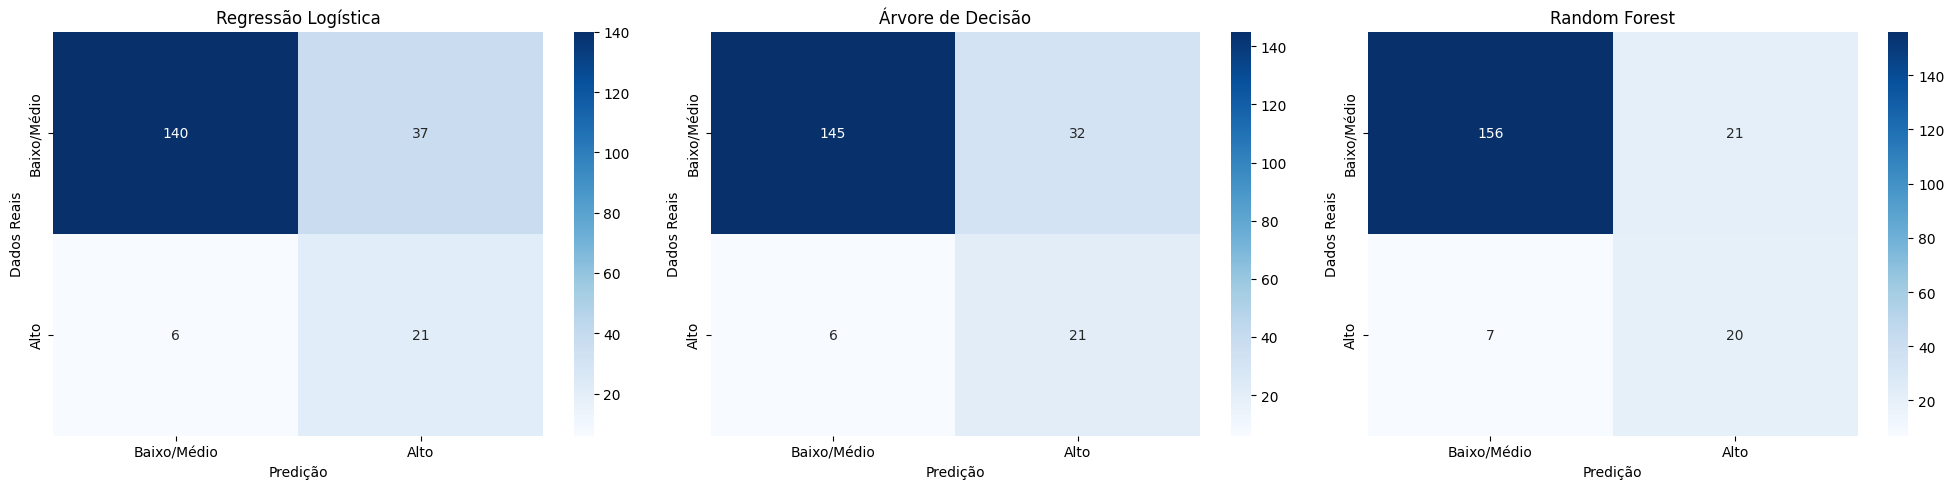

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20,5))
for ax, (nome, y_predito) in zip(axes, predicoes.items()):
    sns.heatmap(confusion_matrix(y_test, y_predito), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Baixo/Médio', 'Alto'], yticklabels=['Baixo/Médio', 'Alto'])
    ax.set_title(nome)
    ax.set_xlabel('Predição')
    ax.set_ylabel('Dados Reais')
plt.tight_layout()
plt.show()

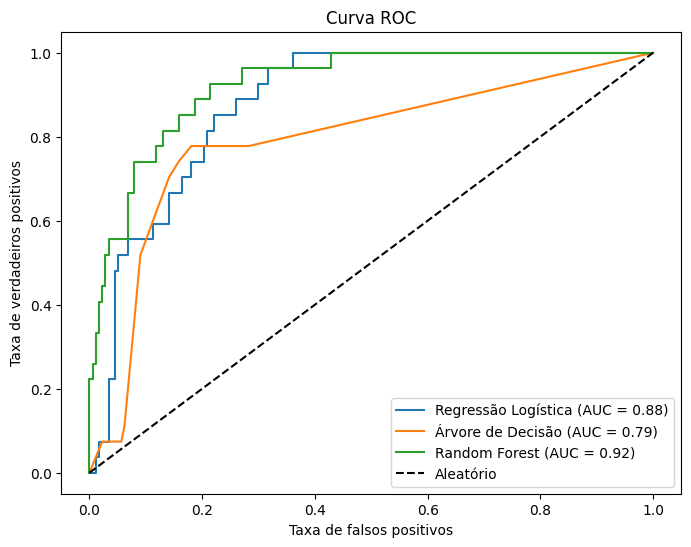

In [ ]:
probabilidades = {
    'Regressão Logística': modelo_regressao_logistica.predict_proba(X_test)[:, 1],
    'Árvore de Decisão': arvore_decisao.predict_proba(X_test)[:, 1],
    'Random Forest': arvore_random.predict_proba(X_test)[:, 1]
}

plt.figure(figsize=(8,6))
for nome, prob in probabilidades.items():
    fpr, tpr, limites = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{nome} (AUC = {roc_auc_score(y_test, prob):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.title('Curva ROC')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos')
plt.legend()
plt.show()

Pontos principais da comparação:
- Predizendo sempre Baixo/Médio já se tem 87% de acurácia no teste, então a acurácia sozinha não mostra se o modelo é bom. Por isso comparamos pelo F1, precisão e recall da classe Alto.
- Os três modelos encontraram 21 dos 27 vinhos Alto (recall de 0,78) olhando o cenário da empresa, seria prejuízo classificar um vinho alto como baixo.
- A diferença está nos falso positivo, ou seja, vinhos Baixo/Médio marcados como Alto: 22 no Random Forest, 32 na Árvore de Decisão e 37 na Regressão Logística.
- O Random Forest teve o melhor resultado: F1 de 0,60, AUC de 0,92 e o melhor F1 na validação cruzada (0,54). Com precisão de 0,49, de cada 2 vinhos que ele aponta como Alto, 1 realmente é.
- A Regressão Logística teve AUC de 0,88, mas precisão de 0,36: de cada 3 vinhos que ela aponta como Alto, só 1 realmente é.
- A Árvore de Decisão ficou no meio no F1 (0,53), mas teve a menor AUC (0,79).

O Random Forest foi o melhor tanto na validação cruzada quanto no teste, então é o modelo que escolhemos.

O teste tem só 27 vinhos Alto, então diferenças de 1 ou 2 vinhos entre os modelos estão dentro da variação esperada. Por isso a validação cruzada é importante para confirmar a escolha.

## 6. Importância das variáveis

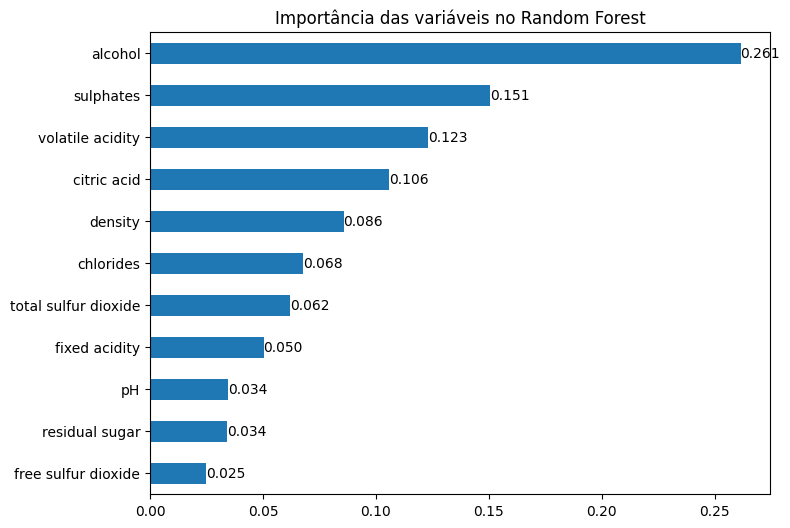

In [ ]:
importancia = pd.Series(arvore_random.named_steps['modelo'].feature_importances_, index=X.columns).sort_values()
ax = importancia.plot(kind='barh', figsize=(8,6))
ax.bar_label(ax.containers[0], fmt='%.3f')
plt.title('Importância das variáveis no Random Forest')
plt.show()

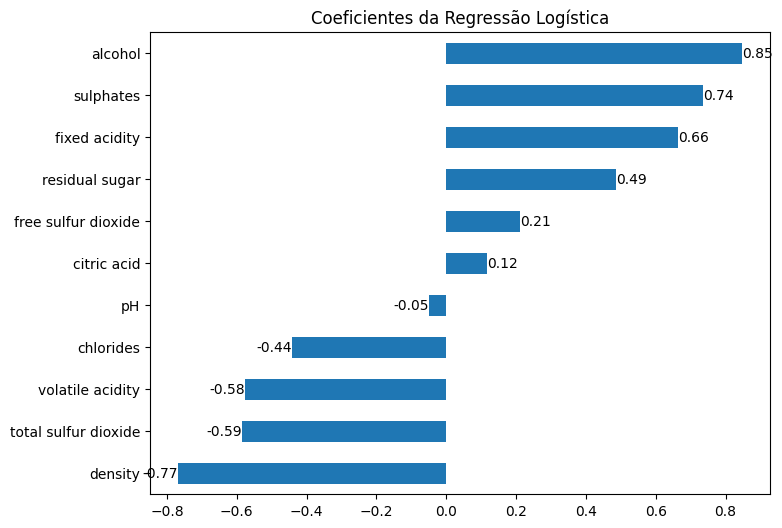

In [ ]:
coeficientes = pd.Series(modelo_regressao_logistica.named_steps['modelo'].coef_[0], index=X.columns).sort_values()
ax = coeficientes.plot(kind='barh', figsize=(8,6))
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.title('Coeficientes da Regressão Logística')
plt.show()

No Random Forest, as variáveis que mais se destacaram foram alcohol, sulphates e volatile acidity. Elas também foram as que apresentaram diferenças mais evidentes entre as categorias durante a análise exploratória. Em seguida, aparecem citric acid e density, que também apresenta uma relação com o teor alcoólico.

Na Regressão Logística, os coeficientes indicam como cada variável está relacionada à probabilidade de um vinho ser classificado como Alto. Coeficientes positivos favorecem essa classificação, enquanto os negativos estão associados a uma menor probabilidade. Nesse caso, alcohol (+0,85) e sulphates (+0,74) apresentam os maiores valores positivos. Já volatile acidity (-0,58) está entre as variáveis com maior associação negativa. Esses resultados são semelhantes aos encontrados no Random Forest.

É importante considerar, porém, que algumas variáveis possuem relações entre si. Isso acontece, por exemplo, com density e alcohol, com as variáveis relacionadas à acidez e com as medidas de SO2. Por esse motivo, os coeficientes da Regressão Logística não devem ser interpretados isoladamente. A variável density, por exemplo, apresenta um coeficiente de -0,77, mas parte dessa relação pode estar associada à sua correlação com o álcool.

Possíveis aplicações na produção

Os resultados permitem levantar algumas hipóteses sobre como as características físico-químicas podem ser utilizadas no acompanhamento da produção. Essas interpretações são baseadas nas relações encontradas nos dados e não comprovam uma relação de causa e efeito.

Álcool: o teor alcoólico pode estar relacionado ao estágio de maturação das uvas e ao andamento da fermentação. Por isso, acompanhar esses fatores pode ajudar a entender melhor as características associadas aos vinhos de maior qualidade.

Acidez volátil: foi uma das variáveis com maior associação negativa com a qualidade. Como está relacionada principalmente à presença de ácido acético, seu monitoramento pode ajudar a identificar possíveis alterações durante a produção. Cuidados com a higiene, a exposição ao oxigênio e o controle da temperatura também podem contribuir para evitar problemas.

Sulfatos: os vinhos classificados como Alto apresentaram valores maiores dessa variável. Como os sulfatos estão relacionados à proteção do vinho contra alterações indesejadas, acompanhar seus níveis pode ser útil durante a produção, respeitando as características e os limites adequados para cada vinho.

Aplicação prática do modelo

Os resultados obtidos indicam que o Random Forest consegue identificar aproximadamente 8 em cada 10 vinhos da categoria Alto. Por outro lado, cerca de metade dos vinhos classificados pelo modelo como Alto realmente pertence a essa categoria. Isso mostra que o modelo pode ser útil para uma primeira seleção dos lotes, mas ainda apresenta limitações nas previsões.

Na prática, a ferramenta poderia ajudar a vinícola a definir quais lotes devem ser avaliados primeiro por meio da prova sensorial. Dessa forma, as análises de laboratório serviriam como apoio à tomada de decisão, sem substituir a avaliação dos especialistas.

Por fim, é importante destacar que as correlações encontradas não comprovam que uma variável seja responsável por aumentar a qualidade do vinho. Um teor alcoólico mais elevado, por exemplo, não significa necessariamente que o vinho será melhor. O objetivo do modelo é identificar padrões presentes nos dados para auxiliar na classificação dos lotes.